# 02 - Radioactive decay and half-life

**MATH 331 - Differential Equations.** Lecture plan: Sessions 4 and 7 (decay as a separable equation; half-life; radiocarbon dating).

**References**
* W.A. Adkins and M.G. Davidson, *Ordinary Differential Equations* (Springer, 2012), Sections 1.1
  and 1.3: the law of radioactive decay, half-life (eq. (12)), radiocarbon dating (Example 8;
  Exercise 32).
* J. Lebl, *Notes on Diffy Qs*: Section 1.3 (separable equations).
* Related notebooks: 01 (the same equation with growth), 10 (separable equations), 13 (time
  constants), **02E** (optional: decay chains).

**What you will learn**
1. The law of decay as an initial value problem, and its solution.
2. Half-life and mean lifetime: what they mean and how they are related.
3. Radiocarbon dating, and how accurate it can be.

## 1. Theory in brief

**The law.** $N(t)$ is the number of radioactive atoms (or the mass of the isotope). The atoms
disintegrate at a rate proportional to their number:

$$ \boxed{\;\frac{dN}{dt} = -\lambda\,N, \qquad N(0) = N_0, \qquad \lambda > 0\;} $$

$\lambda$ is the **decay constant** (units 1/time). It is the equation of notebook 01 with
$k = -\lambda$.

**The solution.** $\;N(t) = N_0\,e^{-\lambda t}$.

**Half-life** $T_{1/2}$: the time after which half of the atoms are left.

$$ T_{1/2} = \frac{\ln 2}{\lambda}, \qquad N(t) = N_0\,2^{-t/T_{1/2}} . $$

**Mean lifetime** $\tau$: the average life of an atom, $\tau = \dfrac{1}{\lambda} \approx 1.44\,T_{1/2}$.
After a time $\tau$ a fraction $1/e \approx 37\,\%$ is left: $\tau$ is the *time constant* of
notebook 13.

**Dating.** If a fraction $f$ of the original amount is left, the age is
$\;t = -\dfrac{\ln f}{\lambda} = -T_{1/2}\,\dfrac{\ln f}{\ln 2}$.

In [1]:
# --- Setup ---------------------------------------------------------------------
# odelib.py lives next to the notebooks: it contains the tested helper functions
# (here: decay_constant, half_life, age_from_fraction, exponential_solution, check).
import sys
import pathlib
sys.path.insert(0, str(pathlib.Path.cwd()))

import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp                      # noqa: F401  (not used in every notebook)
from IPython.display import Math, display                 # noqa: F401
from ipywidgets import FloatSlider, IntSlider, interact    # noqa: F401

import odelib as ol

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "font.size": 11, "legend.fontsize": 9})
print("numpy", np.__version__, "| sympy", sp.__version__)

numpy 2.5.4 | sympy 1.14.0


## 2. The law of decay

A radioactive atom has, in each short time $dt$, the same small probability $\lambda\,dt$ of
disintegrating, whatever its age and whatever the other atoms do. With a very large number of
atoms, the number that disintegrate in the time $dt$ is $\lambda N\,dt$: the rate is proportional
to how many are left. This is the law of radioactive decay (Adkins and Davidson, Section 1.1,
Example 2).

$$ \frac{dN}{dt} = -\lambda\,N . $$

The equation describes the **average** behaviour of a random process; for the enormous numbers
of atoms in a sample, the average is all one sees.

It is separable (notebook 10), and it is solved exactly as in notebook 01:
$\;\dfrac{dN}{N} = -\lambda\,dt$, $\;\ln N = -\lambda t + C$, $\;N = N_0\,e^{-\lambda t}$.

## 3. Half-life and mean lifetime

**Half-life.** By hand: $N(T_{1/2}) = \tfrac12 N_0$ means $e^{-\lambda T_{1/2}} = \tfrac12$, so
$T_{1/2} = \dfrac{\ln 2}{\lambda}$ (Adkins and Davidson, eq. (12); **careful:** that book writes
$\tau$ for the half-life, while here $\tau$ is the mean lifetime). $N_0$ has disappeared: going
from 2 g to 1 g takes as long as going from 1 g to half a gram. After $n$ half-lives a fraction
$2^{-n}$ is left.

**Mean lifetime.** The fraction of atoms still alive at time $t$ is $e^{-\lambda t}$, and the
fraction that disintegrates between $t$ and $t + dt$ is $\lambda e^{-\lambda t}\,dt$. The average
life is therefore

$$ \tau = \int_0^\infty t\,\lambda e^{-\lambda t}\,dt = \frac{1}{\lambda} $$

(integration by parts, video R03).

In [2]:
t, rate, T = sp.symbols("t lambda T", positive=True)
N_0 = sp.symbols("N_0", positive=True)

decay = N_0 * sp.exp(-rate * t)
assert sp.simplify(sp.diff(decay, t) + rate * decay) == 0              # it solves N' = -lambda N

half = sp.solve(sp.Eq(decay.subs(t, T), N_0 / 2), T)[0]
mean = sp.integrate(t * rate * sp.exp(-rate * t), (t, 0, sp.oo))
print("half-life     :", half)
print("mean lifetime :", mean)
print("mean lifetime / half-life =", sp.simplify(mean / half), "=", round(float(1 / sp.log(2)), 4))
print("fraction left after one mean lifetime:", round(float(sp.exp(-1)), 4))

assert half == sp.log(2) / rate and mean == 1 / rate
# the two ways of writing the solution are the same function
assert sp.simplify(decay - N_0 * 2 ** (-t / half)) == 0

half-life     : log(2)/lambda
mean lifetime : 1/lambda
mean lifetime / half-life = 1/log(2) = 1.4427
fraction left after one mean lifetime: 0.3679


The picture, for carbon-14 (half-life 5730 years), on ordinary axes and with a logarithmic
vertical axis. As in notebook 01, on the logarithmic axis the exponential is a **straight line**;
its slope is $-\lambda$. This is how a decay constant is measured.

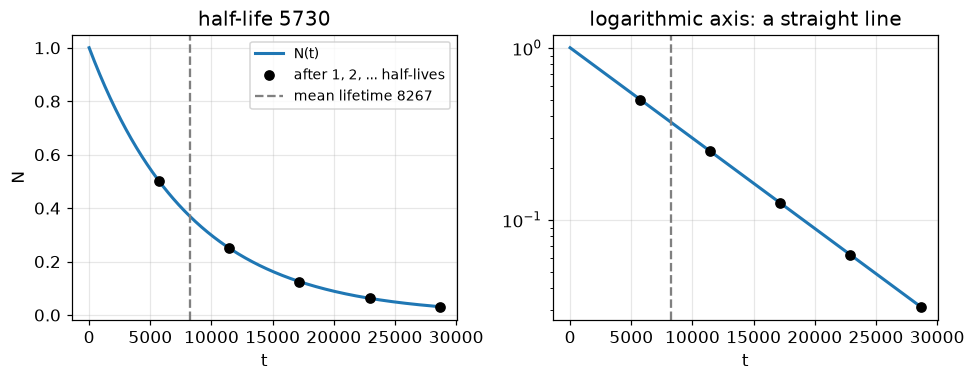

In [3]:
CARBON_HALF_LIFE = 5730.0                   # years
WIDE_FIGURE = (9.0, 3.6)
FIGURE_SIZE = (7.0, 4.0)
N_POINTS = 400


def plot_decay(half_life=CARBON_HALF_LIFE, N0=1.0, n_half_lives=5):
    # N(t) on ordinary and logarithmic axes, with the half-lives and the mean lifetime marked
    lam = ol.decay_constant(half_life)
    times = np.linspace(0.0, n_half_lives * half_life, N_POINTS)
    marks = half_life * np.arange(1, int(n_half_lives) + 1)
    fig, axes = plt.subplots(1, 2, figsize=WIDE_FIGURE)
    for ax in axes:
        ax.plot(times, ol.exponential_solution(times, N0, -lam), "-", linewidth=2, label="N(t)")
        ax.plot(marks, ol.exponential_solution(marks, N0, -lam), "o", color="black", label="after 1, 2, ... half-lives")
        ax.axvline(1 / lam, linestyle="--", color="gray", label=f"mean lifetime {1 / lam:.4g}")
        ax.set_xlabel("t")
    axes[0].set_ylabel("N")
    axes[0].set_title(f"half-life {half_life:.4g}")
    axes[0].legend(loc="upper right")
    axes[1].set_yscale("log")
    axes[1].set_title("logarithmic axis: a straight line")
    plt.tight_layout()
    plt.show()


plot_decay()

*The plot shows* the amount of carbon-14 over five half-lives, twice. On the left it falls from
1 quickly at first and then more and more slowly; the black dots, one per half-life, are at
$\tfrac12, \tfrac14, \tfrac18, \tfrac1{16}, \tfrac1{32}$. On the right, with a logarithmic axis,
the same curve is a straight line going down and the dots are equally spaced along it. The
dashed vertical line is the mean lifetime, 8267 years, later than the first half-life.

**Sliders.** Answer *before* moving them:

1. If the initial amount is doubled, does the half-life change? Does the straight line on the
   right change slope?
2. If the half-life is halved, where does the dashed line go?

In [4]:
HALF_LIFE_RANGE = (500.0, 10000.0, 10.0)        # minimum, maximum, step
AMOUNT_RANGE = (0.1, 10.0, 0.1)
WINDOW_RANGE = (1, 10)                          # half-lives shown

interact(plot_decay,
         half_life=FloatSlider(value=CARBON_HALF_LIFE, min=HALF_LIFE_RANGE[0], max=HALF_LIFE_RANGE[1],
                               step=HALF_LIFE_RANGE[2], description="half-life", continuous_update=False),
         N0=FloatSlider(value=1.0, min=AMOUNT_RANGE[0], max=AMOUNT_RANGE[1], step=AMOUNT_RANGE[2],
                        description="N(0)", continuous_update=False),
         n_half_lives=IntSlider(value=5, min=WINDOW_RANGE[0], max=WINDOW_RANGE[1],
                                description="window", continuous_update=False));

interactive(children=(FloatSlider(value=5730.0, continuous_update=False, description='half-life', max=10000.0,...

(1: no and no; the line moves up, parallel to itself. 2: to half its value: the mean lifetime is
always 1.44 half-lives.)

## 4. Radiocarbon dating

Carbon-14 is produced in the atmosphere and enters every living organism, which keeps the same
proportion of it as the air. After death no new carbon comes in, and the carbon-14 decays with a
half-life of 5730 years. Measuring the fraction $f$ that is left gives the age:

$$ f = e^{-\lambda t} \quad\Longrightarrow\quad t = -\frac{\ln f}{\lambda} = -T_{1/2}\,\frac{\ln f}{\ln 2} . $$

*Adkins and Davidson, Section 1.3, Example 8.* A sample of wood contains 75 % of the carbon-14 of
a sample of wood found today. How old is it?

By hand: $t = -5730\,\dfrac{\ln 0.75}{\ln 2} \approx 2378$ years.

In [5]:
FRACTION_LEFT = 0.75

wood_age = ol.age_from_fraction(FRACTION_LEFT, CARBON_HALF_LIFE)
print(f"age of the wood: {wood_age:.1f} years")
assert abs(wood_age - 2378) < 0.5               # Adkins and Davidson, Example 8

age of the wood: 2378.2 years


**How accurate is the age?** The fraction is measured with an error $\delta f$. Since
$\dfrac{dt}{df} = -\dfrac{1}{\lambda f}$, the age is uncertain by about

$$ |\delta t| \approx \frac{\delta f}{\lambda\,f} . $$

The uncertainty grows as $f$ gets small: **old samples are harder to date**. The picture shows
the age against the fraction left, and what an uncertainty in the fraction does to the age.

Two more cautions. The proportion of carbon-14 in the atmosphere has not been constant, so
laboratories correct the ages with calibration tables (Adkins and Davidson, footnote 7, Section
1.3). And by convention "radiocarbon ages" are first computed with an older value of the
half-life, 5568 years, and then corrected.

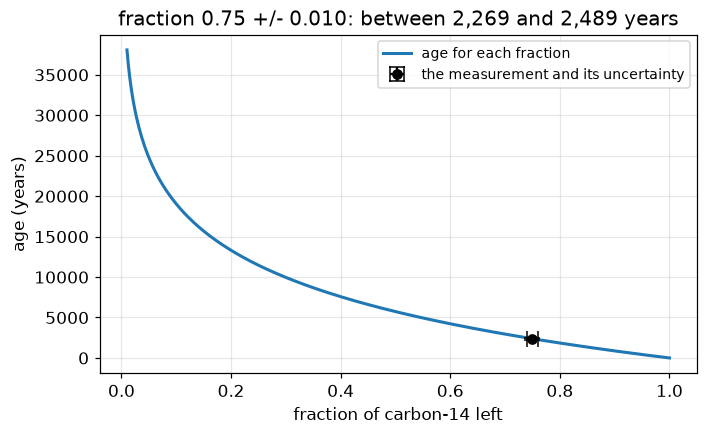

In [6]:
SMALLEST_FRACTION = 0.01
UNCERTAINTY = 0.01


def plot_dating(fraction=FRACTION_LEFT, delta_f=UNCERTAINTY):
    # the age against the fraction left, with the effect of an uncertainty delta_f
    fractions = np.linspace(SMALLEST_FRACTION, 1.0, N_POINTS)
    best = ol.age_from_fraction(fraction, CARBON_HALF_LIFE)
    youngest = ol.age_from_fraction(min(fraction + delta_f, 1.0), CARBON_HALF_LIFE)
    oldest = ol.age_from_fraction(max(fraction - delta_f, SMALLEST_FRACTION / 10), CARBON_HALF_LIFE)
    fig, ax = plt.subplots(figsize=FIGURE_SIZE)
    ax.plot(fractions, -np.log(fractions) / ol.decay_constant(CARBON_HALF_LIFE), "-", linewidth=2,
            label="age for each fraction")
    ax.errorbar([fraction], [best], xerr=[[delta_f], [delta_f]], yerr=[[best - youngest], [oldest - best]],
                fmt="o", color="black", capsize=5, label="the measurement and its uncertainty")
    ax.set_xlabel("fraction of carbon-14 left")
    ax.set_ylabel("age (years)")
    ax.set_title(f"fraction {fraction:.2f} +/- {delta_f:.3f}: between {youngest:,.0f} and {oldest:,.0f} years")
    ax.legend(loc="upper right")
    plt.show()


plot_dating()

*The plot shows* the age (vertical axis) for each fraction of carbon-14 left (horizontal axis): a
curve that is 0 at fraction 1 and rises steeply towards the left, where little carbon-14 is
left. The black dot is the wood of the example, at 0.75 and 2378 years; its small bars show that
an uncertainty of 0.01 in the fraction means about 110 years either way.

**Sliders.** Before moving them: with the same uncertainty of 0.01, is the age of a sample with
10 % of its carbon-14 known better or worse than the age of the wood? Why (look at the slope of
the curve)?

In [7]:
FRACTION_RANGE = (0.02, 0.99, 0.01)             # minimum, maximum, step
DELTA_RANGE = (0.001, 0.05, 0.001)

interact(plot_dating,
         fraction=FloatSlider(value=FRACTION_LEFT, min=FRACTION_RANGE[0], max=FRACTION_RANGE[1],
                              step=FRACTION_RANGE[2], description="fraction", continuous_update=False),
         delta_f=FloatSlider(value=UNCERTAINTY, min=DELTA_RANGE[0], max=DELTA_RANGE[1], step=DELTA_RANGE[2],
                             readout_format=".3f", description="uncertainty", continuous_update=False));

interactive(children=(FloatSlider(value=0.75, continuous_update=False, description='fraction', max=0.99, min=0...

(Worse: where little is left the curve is steep, so a small change of the fraction is a large
change of the age.)

## 5. The same equation elsewhere

* A capacitor $C$ that discharges through a resistor $R$: $V' = -\dfrac{V}{RC}$. The mean lifetime
  is the **time constant** $RC$ of notebook 13, and the half-life is $RC\ln 2$.
* Many isotopes decay into another radioactive isotope, which decays in turn. The second
  equation is then linear and not homogeneous, and needs the integrating factor of notebook 11:
  this is the optional notebook **02E, Decay chains**.

## 6. Exercises

Final answers are at the end; try first.

**Before you start:** run the whole notebook (the `>>` button at the top, then *Confirm Kernel Restart*; or the menu *Run > Run All Cells*), every time you open it: the exercises use what the
cells above define. In an answer cell change only the lines above the line that starts with `# ----`, then press Shift+Enter. If Python does not accept what you type, see "How to type
mathematics" in notebook 00, or click `+` at the top, type `ol.guide("typing")` in the new cell and press Shift+Enter.

### Exercise 1 - Predict (no computer)

What fraction of a radioactive sample is left

* after three half-lives?
* after one mean lifetime? (Two decimals.)

Type the two numbers in a list.

In [8]:
my_fractions = None             # [after three half-lives, after one mean lifetime]
# ---- your answers go above this line; the lines below check them (nothing to change) ----

TWO_DECIMALS = 1e-2
ol.check("Exercise 1", my_fractions, [2.0 ** -3, np.exp(-1.0)], tol=TWO_DECIMALS);

Exercise 1: no answer yet (replace None with your value)


### Exercise 2 - By hand, then check

**(a)** *Adkins and Davidson, Section 1.3, Exercise 32.* A human bone is found in a melting
glacier. Its carbon-14 content is only one third of that of a similar bone today. Estimate its
age, in years.

**(b)** The same for a sample with 10 % of its carbon-14.

**(c)** A sample of another isotope loses 20 % of its atoms in 10 days. What is its half-life, in
days?

In [9]:
my_age_third = None             # (a), years
my_age_tenth = None             # (b), years
my_half_life = None             # (c), days
# ---- your answers go above this line; the lines below check them (nothing to change) ----

ONE_PER_CENT = 1e-2
LOST, DAYS = 0.20, 10.0
expected_half_life = ol.half_life(-np.log(1 - LOST) / DAYS)

ol.check("Exercise 2a", my_age_third, ol.age_from_fraction(1 / 3, CARBON_HALF_LIFE), tol=ONE_PER_CENT)
ol.check("Exercise 2b", my_age_tenth, ol.age_from_fraction(0.10, CARBON_HALF_LIFE), tol=ONE_PER_CENT)
ol.check("Exercise 2c", my_half_life, expected_half_life, tol=2 * ONE_PER_CENT);     # lambda rounded to 0.022 is fine

Exercise 2a: no answer yet (replace None with your value)
Exercise 2b: no answer yet (replace None with your value)
Exercise 2c: no answer yet (replace None with your value)


### Exercise 3 - Fill in

Complete the function `age`, which returns the age of a sample from the fraction of the isotope
that is left and from the half-life: use the formula of Section 1 (`np.log` is the natural
logarithm). The next cell tries it on the wood of Adkins and Davidson.

In [10]:
def age(fraction, half_life):
    return None                 # replace None with the formula

In [11]:
if age(FRACTION_LEFT, CARBON_HALF_LIFE) is None:
    print("Exercise 3: complete age first")
else:
    assert abs(age(FRACTION_LEFT, CARBON_HALF_LIFE) - 2378) < 0.5, "the wood of Example 8 is 2378 years old"
    assert np.isclose(age(0.5, CARBON_HALF_LIFE), CARBON_HALF_LIFE), "half of it is left after one half-life"
    assert np.isclose(age(1.0, CARBON_HALF_LIFE), 0.0), "nothing has decayed: the age is zero"
    assert np.isclose(age(0.25, DAYS), 2 * DAYS), "a quarter is left after two half-lives, whatever the half-life"
    print(f"Exercise 3: correct, {age(FRACTION_LEFT, CARBON_HALF_LIFE):.0f} years for the wood")

Exercise 3: complete age first


### Exercise 4 - Explore

The fraction of carbon-14 is measured with an uncertainty of 0.005.

* Use the formula $|\delta t| \approx \delta f / (\lambda f)$ to estimate the uncertainty of the
  age of the wood (75 % left) and of the sample of Exercise 2(b) (10 % left).
  `ol.decay_constant(CARBON_HALF_LIFE)` gives $\lambda$.
* Check your two numbers with the sliders of Section 4.
* Carbon-14 dating is not used beyond about 50 000 years. What fraction is left then?

In [12]:
# your code here

## 7. Answers

Final answers only; full solutions are given after the session.

<details>
<summary>Click to open (after trying)</summary>

1. $2^{-3} = 0.125$ and $1/e \approx 0.37$.
2. (a) $5730\,\dfrac{\ln 3}{\ln 2} \approx 9082$ years. (b) $5730\,\dfrac{\ln 10}{\ln 2} \approx 19\,035$
   years. (c) $e^{-10\lambda} = 0.8$ gives $\lambda = 0.0223$ per day and
   $T_{1/2} = \ln 2/\lambda \approx 31.1$ days.
3. `return -half_life * np.log(fraction) / np.log(2)`
4. About 55 years for the wood and about 413 years for the 10 % sample: seven and a half times
   worse, because $1/f$ is seven and a half times larger. After 50 000 years the fraction left is
   $2^{-50000/5730} \approx 0.002$: too little to measure well.

</details>

**Where to go next:** notebook 02E (decay chains, optional), notebook 03 (the logistic equation).